Physical no-filter development frames: 826
Development sessions from filenames: [2, 3, 4, 5, 6, 7, 8]
All Background files: 474
Independent Background files used: 61
Background copies excluded: 413


class_name,Clean air,HFC,All
session,,,
2,59,59,118
3,59,59,118
4,59,59,118
5,59,59,118
6,59,59,118
7,59,59,118
8,59,59,118
All,413,413,826


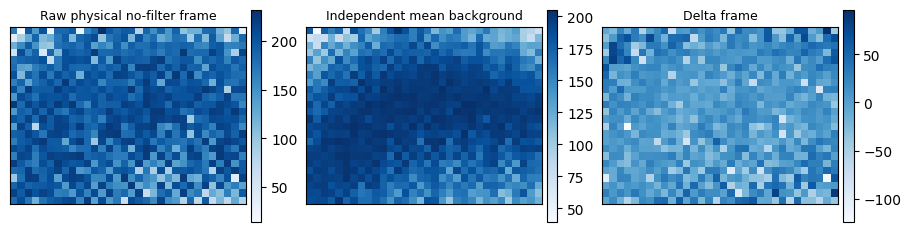


NO-FILTER FOLD 1/5

Epoch 1/50
130/130 - 4s - 30ms/step - accuracy: 0.5189 - loss: 0.8719 - val_accuracy: 0.5381 - val_loss: 0.6893
Epoch 2/50
130/130 - 2s - 13ms/step - accuracy: 0.5901 - loss: 0.6690 - val_accuracy: 0.5678 - val_loss: 0.6850
Epoch 3/50
130/130 - 2s - 13ms/step - accuracy: 0.6748 - loss: 0.5977 - val_accuracy: 0.5127 - val_loss: 0.8079
Epoch 4/50
130/130 - 2s - 13ms/step - accuracy: 0.7751 - loss: 0.4548 - val_accuracy: 0.5636 - val_loss: 0.8820
Epoch 5/50
130/130 - 2s - 13ms/step - accuracy: 0.8552 - loss: 0.3276 - val_accuracy: 0.5508 - val_loss: 1.4007
Epoch 6/50
130/130 - 2s - 13ms/step - accuracy: 0.8864 - loss: 0.2652 - val_accuracy: 0.5890 - val_loss: 1.2617
Epoch 7/50
130/130 - 2s - 13ms/step - accuracy: 0.9245 - loss: 0.1847 - val_accuracy: 0.5551 - val_loss: 1.5052
Epoch 8/50
130/130 - 2s - 13ms/step - accuracy: 0.9513 - loss: 0.1297 - val_accuracy: 0.5805 - val_loss: 1.9143
Epoch 9/50
130/130 - 2s - 13ms/step - accuracy: 0.9591 - loss: 0.1165 - val_accurac

,fold,n_train_sources,n_train_inputs,n_validation_original,best_epoch,accuracy,macro_precision,macro_recall,macro_f1
0,1,590,4130,236,2,0.5678,0.5725,0.5678,0.5607
1,2,708,4956,118,3,0.6610,0.6929,0.6610,0.6464
2,3,708,4956,118,2,0.5424,0.5424,0.5424,0.5422
3,4,590,4130,236,3,0.6017,0.6036,0.6017,0.5999
4,5,708,4956,118,1,0.5254,0.5343,0.5254,0.4926


,n_source_frames,pooled_accuracy,pooled_macro_precision,pooled_macro_recall,pooled_macro_f1,fold_accuracy_mean,fold_accuracy_sample_sd,best_epochs
0,826,0.5811,0.5832,0.5811,0.5784,0.5797,0.0538,"[2, 3, 2, 3, 1]"


Best epochs by fold: [2, 3, 2, 3, 1]
Fixed final epochs: 2
Epoch 1/2
181/181 - 4s - 23ms/step - accuracy: 0.5144 - loss: 0.8311
Epoch 2/2
181/181 - 2s - 13ms/step - accuracy: 0.5545 - loss: 0.6817


,n,accuracy,macro_precision,macro_recall,macro_f1
0,236,0.5424,0.5571,0.5424,0.5107


,session,n,accuracy,macro_precision,macro_recall,macro_f1
0,15,118,0.5254,0.5360,0.5254,0.4878
1,16,118,0.5593,0.5766,0.5593,0.5330


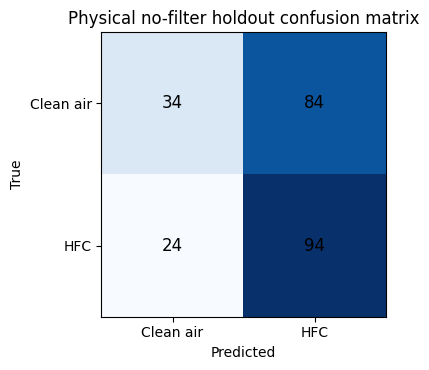

,configuration,cv_pooled_accuracy,cv_macro_f1,holdout_accuracy,holdout_macro_f1
0,Physical no-filter,0.5811,0.5784,0.5424,0.5107
1,Four-region filtered baseline,0.8029,0.8026,0.8967,0.8966


INTERPRETATION LIMIT: The physical no-filter data were acquired separately from the filtered dataset. Therefore, the numerical difference is descriptive and cannot be attributed exclusively to filter removal.

DONE
Output folder: C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_no_filter_outputs
ZIP artifact : C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_no_filter_outputs.zip
CV summary   : {'n_source_frames': 826, 'pooled_accuracy': 0.5811138014527845, 'pooled_macro_precision': 0.5832395781316744, 'pooled_macro_recall': 0.5811138014527846, 'pooled_macro_f1': 0.5784222327118245, 'fold_accuracy_mean': 0.5796610169491525, 'fold_accuracy_sample_sd': 0.053798543213911434, 'best_epochs': [2, 3, 2, 3, 1], 'final_epochs': 2}
Holdout      : {'n': 236, 'accuracy': 0.5423728813559322, 'macro_precision': 0.5571483920960867, 'macro_recall': 0.5423728813559322, 'macro_f1': 0.5107493857493857}


In [3]:
"""PHYSICAL NO-FILTER CONTROL — IJIES, one-cell training and evaluation pipeline.

Required folder structure:
NO_FILTER_TRAIN_ROOT/
    Background/*.csv
    Clean Air/*.csv
    HFC/*.csv
NO_FILTER_HOLDOUT_ROOT/        # optional
    Clean Air/*.csv
    HFC/*.csv

Each CSV must contain one 24 x 32 frame. This code is intended only for images
acquired physically without the filter assembly; it is not a software mask.
"""

# ============================================================================
# 0. INSTALL MISSING PACKAGES
# ============================================================================
import importlib.util, subprocess, sys

REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "cv2": "opencv-python-headless",
    "sklearn": "scikit-learn", "matplotlib": "matplotlib", "tensorflow": "tensorflow",
}
missing = [package for module, package in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

# ============================================================================
# 1. CONFIGURATION — EDIT THESE PATHS BEFORE RUNNING
# ============================================================================
from pathlib import Path
import os

PROJECT_ROOT = Path(os.environ.get(
    "IJIES_PROJECT_ROOT", r"C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project"
))
NO_FILTER_TRAIN_SOURCE = Path(os.environ.get(
    "IJIES_NO_FILTER_TRAIN_SOURCE",
    r"C:\1. Tukadi_ITS\2. Kumpulan data jurnal2\.data_5(m)\.data_3(m)\X_learning (8)_NO_FILTER.zip",
))
NO_FILTER_HOLDOUT_SOURCE = Path(os.environ.get(
    "IJIES_NO_FILTER_HOLDOUT_SOURCE",
    r"C:\1. Tukadi_ITS\2. Kumpulan data jurnal2\.data_5(m)\.data_3(m)\X_Exsternal  (8)_NO_FILTER.zip",
))
FILTERED_ARTIFACT_DIR = PROJECT_ROOT / "ijies_master_outputs"
OUTPUT_DIR = PROJECT_ROOT / "ijies_no_filter_outputs"

# Set True only when the files were captured with the filter assembly physically removed.
PHYSICAL_NO_FILTER_DATA = True

# Set True only if no-filter and filtered data used matched acquisition sessions/conditions.
# If collected later as a separate experiment, keep False; the code will use cautious wording.
MATCHED_ACQUISITION_TO_FILTERED_DATA = False

EXPECTED_TRAIN_SOURCE = 826        # 7 sessions × 59 frames × 2 classes
EXPECTED_HOLDOUT_SOURCE = 236      # 2 sessions × 59 frames × 2 classes
IMAGES_PER_CLASS_SESSION = 59       # 59 Clean Air + 59 HFC per independent session
N_SPLITS = 5
SEED = 42
MAX_EPOCHS = 50
PATIENCE = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.001
USE_AUGMENTATION = True
FORCE_RERUN = False

# "median_cv" selects the final epoch count only from grouped development folds.
# Use an integer (for example 4) only if a fixed epoch count was preregistered.
FINAL_EPOCH_POLICY = "median_cv"

# Colab example:
# from google.colab import drive
# drive.mount('/content/drive')
# PROJECT_ROOT = Path('/content/drive/MyDrive/Artefak ID 20266063')
# NO_FILTER_TRAIN_ROOT = PROJECT_ROOT / 'X_learning5_no_filter'
# NO_FILTER_HOLDOUT_ROOT = PROJECT_ROOT / 'X_testing5_no_filter'
# OUTPUT_DIR = PROJECT_ROOT / 'ijies_no_filter_outputs'

# ============================================================================
# 2. IMPORTS, REPRODUCIBILITY, AND BASIC HELPERS
# ============================================================================
import hashlib, json, platform, random, re, shutil, time, warnings, zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_recall_fscore_support
)
from sklearn.model_selection import StratifiedGroupKFold
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, MaxPooling2D, Flatten, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)

if not PHYSICAL_NO_FILTER_DATA:
    raise ValueError("Set PHYSICAL_NO_FILTER_DATA=True only after confirming physical no-filter acquisition.")
if not NO_FILTER_TRAIN_SOURCE.exists():
    raise FileNotFoundError(f"Training dataset not found: {NO_FILTER_TRAIN_SOURCE}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LABEL_TO_ID = {"Clean air": 0, "HFC": 1}
ID_TO_LABEL = {0: "Clean air", 1: "HFC"}
VARIANT_NAMES = [
    "original", "rotation_+5deg", "rotation_-5deg", "intensity_+15",
    "intensity_-15", "center_zoom_1.1x", "gaussian_blur_3x3",
]

def seed_all(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def session_number(path):
    match = re.search(r"\((\d+)\)", Path(path).stem)
    return int(match.group(1)) if match else None

def frame_number(path):
    match = re.search(r"_frame_(\d+)", Path(path).stem, flags=re.IGNORECASE)
    return int(match.group(1)) if match else None

def frame_value_sha256(array):
    return hashlib.sha256(np.ascontiguousarray(array, dtype=np.float32).tobytes()).hexdigest()

def natural_sort_key(path):
    # Sorts file1, file2, ..., file10 correctly even when '(n)' is absent/repeated.
    return [int(token) if token.isdigit() else token.lower()
            for token in re.split(r"(\d+)", Path(path).name)]

def read_frame(path):
    array = pd.read_csv(path, header=None).to_numpy(dtype=np.float32)
    if array.shape == (24, 32):
        return array
    if array.size == 768:
        return array.reshape(24, 32)
    raise ValueError(f"Invalid frame shape {array.shape}: {path}")

def materialize_dataset(source, cache_name):
    source = Path(source)
    if source.is_dir():
        return source
    if source.suffix.lower() != ".zip":
        raise ValueError(f"Dataset must be a folder or ZIP: {source}")
    destination = OUTPUT_DIR / cache_name
    marker = destination / ".source_sha256"
    current_hash = sha256_file(source)
    if FORCE_RERUN or not marker.exists() or marker.read_text(encoding="utf-8") != current_hash:
        if destination.exists():
            shutil.rmtree(destination)
        destination.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(source) as archive:
            for info in archive.infolist():
                target = (destination / info.filename).resolve()
                if destination.resolve() not in target.parents and target != destination.resolve():
                    raise ValueError(f"Unsafe ZIP member: {info.filename}")
            archive.extractall(destination)
        marker.write_text(current_hash, encoding="utf-8")
    children = [path for path in destination.iterdir() if path.is_dir()]
    if len(children) == 1 and not any((destination / name).is_dir() for name in ["Background", "Clean air", "HFC"]):
        return children[0]
    return destination

def find_class_dir(root, requested_name):
    wanted = requested_name.casefold().replace(" ", "")
    candidates = [path for path in Path(root).iterdir() if path.is_dir()]
    for path in candidates:
        if path.name.casefold().replace(" ", "") == wanted:
            return path
    raise FileNotFoundError(f"Folder '{requested_name}' not found under {root}")

seed_all(SEED)
NO_FILTER_TRAIN_ROOT = materialize_dataset(NO_FILTER_TRAIN_SOURCE, "_extracted_no_filter_train")
NO_FILTER_HOLDOUT_ROOT = (
    materialize_dataset(NO_FILTER_HOLDOUT_SOURCE, "_extracted_no_filter_holdout")
    if NO_FILTER_HOLDOUT_SOURCE.exists() else None
)

# ============================================================================
# 3. LOAD PHYSICAL NO-FILTER DEVELOPMENT DATA AND INDEPENDENT BACKGROUND
# ============================================================================
source_rows, raw_frames, labels, groups = [], [], [], []
train_class_dirs = {name: find_class_dir(NO_FILTER_TRAIN_ROOT, name) for name in LABEL_TO_ID}

for class_name, label in LABEL_TO_ID.items():
    paths = sorted(train_class_dirs[class_name].glob("*.csv"), key=natural_sort_key)
    if not paths:
        raise RuntimeError(f"No CSV files found for class: {class_name}")
    for path in paths:
        session = session_number(path)
        frame = frame_number(path)
        if session is None or frame is None:
            raise ValueError(f"Cannot parse session/frame from filename: {path.name}")
        array = read_frame(path)
        source_rows.append({
            "source_index": len(source_rows), "path": str(path), "label": label,
            "class_name": class_name, "session": session, "frame": frame,
            "sha256": sha256_file(path), "value_sha256": frame_value_sha256(array),
        })
        raw_frames.append(array)
        labels.append(label)
        groups.append(session)

source_manifest = pd.DataFrame(source_rows)
raw_frames = np.asarray(raw_frames, dtype=np.float32)
labels = np.asarray(labels, dtype=np.int64)
groups = np.asarray(groups, dtype=np.int64)

# The ZIP contains 413 Background files that are exact copies of the Clean-air
# class frames from sessions 2–8. They are excluded from the reference to avoid
# validation-frame leakage. Only independent Background session 1 is retained.
background_dir = find_class_dir(NO_FILTER_TRAIN_ROOT, "Background")
all_background_paths = sorted(background_dir.glob("*.csv"), key=natural_sort_key)
source_value_hashes = set(source_manifest["value_sha256"])
background_rows, selected_background_frames = [], []
for path in all_background_paths:
    array = read_frame(path)
    value_hash = frame_value_sha256(array)
    duplicate_of_source = value_hash in source_value_hashes
    selected = not duplicate_of_source
    background_rows.append({
        "path": str(path), "session": session_number(path), "frame": frame_number(path),
        "sha256": sha256_file(path), "value_sha256": value_hash,
        "duplicate_of_class_source": duplicate_of_source,
        "selected_for_reference": selected,
    })
    if selected:
        selected_background_frames.append(array)

if not selected_background_frames:
    raise RuntimeError("No background frame independent of the class-source files was found.")
background_frames = np.stack(selected_background_frames).astype(np.float32)
fixed_background = background_frames.mean(axis=0).astype(np.float32)
delta_frames = (raw_frames - fixed_background).astype(np.float32)[..., None]

if EXPECTED_TRAIN_SOURCE is not None and len(raw_frames) != EXPECTED_TRAIN_SOURCE:
    raise ValueError(f"Expected {EXPECTED_TRAIN_SOURCE} source frames, found {len(raw_frames)}")
if len(np.unique(groups)) < N_SPLITS:
    raise ValueError(f"Need at least {N_SPLITS} independent sessions, found {len(np.unique(groups))}")

session_class_counts = pd.crosstab(source_manifest.session, source_manifest.class_name)
if set(session_class_counts.columns) != set(LABEL_TO_ID):
    raise ValueError("Not every class is represented in the session table.")
if not (session_class_counts[list(LABEL_TO_ID)] == IMAGES_PER_CLASS_SESSION).all().all():
    raise ValueError(
        "Every development session must contain exactly "
        f"{IMAGES_PER_CLASS_SESSION} frames per class.\n{session_class_counts}"
    )

background_manifest = pd.DataFrame(background_rows)
source_manifest.to_csv(OUTPUT_DIR / "no_filter_source_manifest.csv", index=False)
background_manifest.to_csv(OUTPUT_DIR / "no_filter_background_manifest.csv", index=False)

print("Physical no-filter development frames:", len(raw_frames))
print("Development sessions from filenames:", sorted(np.unique(groups).tolist()))
print("All Background files:", len(all_background_paths))
print("Independent Background files used:", len(background_frames))
print("Background copies excluded:", int(background_manifest.duplicate_of_class_source.sum()))
display(pd.crosstab(source_manifest.session, source_manifest.class_name, margins=True))

preview_index = 0
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), constrained_layout=True)
for axis, image, title in zip(
    axes,
    [raw_frames[preview_index], fixed_background, delta_frames[preview_index, ..., 0]],
    ["Raw physical no-filter frame", "Independent mean background", "Delta frame"],
):
    artist = axis.imshow(image, cmap="Blues")
    axis.set_title(title, fontsize=9)
    axis.set_xticks([]); axis.set_yticks([])
    fig.colorbar(artist, ax=axis, fraction=0.045, pad=0.02)
plt.show()

# 4. TRAINING-ONLY AUGMENTATION — IDENTICAL RULE TO THE FILTERED PIPELINE
# ============================================================================
def augmentation_variants(raw_frame):
    raw = np.clip(raw_frame, 0, 255).astype(np.uint8)
    height, width = raw.shape
    center = (width // 2, height // 2)

    def rotate(angle):
        matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        return cv2.warpAffine(raw, matrix, (width, height), borderMode=cv2.BORDER_REFLECT)

    new_width, new_height = int(width / 1.1), int(height / 1.1)
    x0, y0 = width // 2 - new_width // 2, height // 2 - new_height // 2
    zoom = cv2.resize(
        raw[y0:y0 + new_height, x0:x0 + new_width],
        (width, height), interpolation=cv2.INTER_LINEAR,
    )
    return [
        raw, rotate(5), rotate(-5),
        np.clip(raw.astype(np.int16) + 15, 0, 255).astype(np.uint8),
        np.clip(raw.astype(np.int16) - 15, 0, 255).astype(np.uint8),
        zoom, cv2.GaussianBlur(raw, (3, 3), 0),
    ]

def prepare_training_inputs(source_raw, source_labels, background):
    if not USE_AUGMENTATION:
        return (source_raw - background).astype(np.float32)[..., None], source_labels.copy()
    total = len(source_raw) * len(VARIANT_NAMES)
    x_out = np.empty((total, 24, 32, 1), dtype=np.float32)
    y_out = np.empty(total, dtype=np.int64)
    cursor = 0
    for frame, label in zip(source_raw, source_labels):
        for variant in augmentation_variants(frame):
            x_out[cursor, ..., 0] = variant.astype(np.float32) - background
            y_out[cursor] = label
            cursor += 1
    return x_out, y_out

# ============================================================================
# 5. CNN DEFINITION AND METRICS
# ============================================================================
def build_cnn():
    model = Sequential([
        Input((24, 32, 1)),
        Conv2D(32, 3, activation="relu", padding="same"),
        BatchNormalization(), MaxPooling2D(2),
        Conv2D(64, 3, activation="relu", padding="same"),
        BatchNormalization(), MaxPooling2D(2),
        Conv2D(128, 3, activation="relu", padding="same"),
        BatchNormalization(), MaxPooling2D(2),
        Flatten(), Dense(128, activation="relu"), Dropout(0.5),
        Dense(2, activation="softmax"),
    ])
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy"],
    )
    return model

def metric_dict(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision, "macro_recall": recall, "macro_f1": f1,
    }

# ============================================================================
# 6. SESSION-GROUPED FIVE-FOLD DEVELOPMENT EVALUATION
# ============================================================================
splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
splits = list(splitter.split(delta_frames, labels, groups))
fold_assignment = np.full(len(labels), -1, dtype=int)
for fold, (train_index, validation_index) in enumerate(splits, 1):
    overlap = set(groups[train_index]) & set(groups[validation_index])
    if overlap:
        raise RuntimeError(f"Session leakage in fold {fold}: {overlap}")
    fold_assignment[validation_index] = fold
source_manifest["validation_fold"] = fold_assignment
source_manifest.to_csv(OUTPUT_DIR / "no_filter_source_manifest.csv", index=False)

fold_metrics, source_predictions, best_epochs = [], [], []
for fold, (train_index, validation_index) in enumerate(splits, 1):
    print(f"\n{'='*72}\nNO-FILTER FOLD {fold}/{N_SPLITS}\n{'='*72}")
    x_train, y_train = prepare_training_inputs(
        raw_frames[train_index], labels[train_index], fixed_background
    )
    x_validation = delta_frames[validation_index]  # original only
    y_validation = labels[validation_index]

    tf.keras.backend.clear_session()
    seed_all(SEED + fold)
    model = build_cnn()
    early_stop = EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
    )
    history = model.fit(
        x_train, to_categorical(y_train, 2),
        validation_data=(x_validation, to_categorical(y_validation, 2)),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[early_stop], verbose=2,
    )
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    best_epochs.append(best_epoch)
    probabilities = model.predict(x_validation, verbose=0)
    predictions = probabilities.argmax(axis=1)
    metrics = metric_dict(y_validation, predictions)
    fold_metrics.append({
        "fold": fold, "n_train_sources": len(train_index),
        "n_train_inputs": len(x_train), "n_validation_original": len(validation_index),
        "best_epoch": best_epoch, **metrics,
    })
    for local_index, source_index in enumerate(validation_index):
        source_predictions.append({
            "source_index": int(source_index),
            "path": source_manifest.iloc[source_index].path,
            "session": int(groups[source_index]) + 1,
            "fold": fold, "true": int(y_validation[local_index]),
            "pred": int(predictions[local_index]),
            "p_hfc": float(probabilities[local_index, 1]),
            "correct": bool(predictions[local_index] == y_validation[local_index]),
        })
    print(f"Fold {fold}: accuracy={metrics['accuracy']:.4f}; best epoch={best_epoch}")
    del model, x_train, y_train

fold_metrics_df = pd.DataFrame(fold_metrics)
source_predictions_df = pd.DataFrame(source_predictions).sort_values("source_index")
fold_metrics_df.to_csv(OUTPUT_DIR / "no_filter_fold_metrics.csv", index=False)
source_predictions_df.to_csv(OUTPUT_DIR / "no_filter_source_predictions.csv", index=False)

pooled = metric_dict(source_predictions_df.true, source_predictions_df.pred)
cv_summary = {
    "n_source_frames": int(len(source_predictions_df)),
    "pooled_accuracy": pooled["accuracy"],
    "pooled_macro_precision": pooled["macro_precision"],
    "pooled_macro_recall": pooled["macro_recall"],
    "pooled_macro_f1": pooled["macro_f1"],
    "fold_accuracy_mean": float(fold_metrics_df.accuracy.mean()),
    "fold_accuracy_sample_sd": float(fold_metrics_df.accuracy.std(ddof=1)),
    "best_epochs": best_epochs,
}
display(fold_metrics_df.round(4))
display(pd.DataFrame([cv_summary]).round(4))

# ============================================================================
# 7. FINAL RETRAINING — HOLDOUT IS NOT USED FOR EPOCH SELECTION
# ============================================================================
if FINAL_EPOCH_POLICY == "median_cv":
    final_epochs = int(np.median(best_epochs))
elif isinstance(FINAL_EPOCH_POLICY, int) and FINAL_EPOCH_POLICY > 0:
    final_epochs = int(FINAL_EPOCH_POLICY)
else:
    raise ValueError("FINAL_EPOCH_POLICY must be 'median_cv' or a positive integer.")

print("Best epochs by fold:", best_epochs)
print("Fixed final epochs:", final_epochs)
all_train_x, all_train_y = prepare_training_inputs(raw_frames, labels, fixed_background)
tf.keras.backend.clear_session()
seed_all(SEED + 1000)
final_model = build_cnn()
final_model.fit(
    all_train_x, to_categorical(all_train_y, 2),
    epochs=final_epochs, batch_size=BATCH_SIZE, verbose=2,
)
final_model_path = OUTPUT_DIR / "no_filter_final_model.keras"
final_model.save(final_model_path)
cv_summary["final_epochs"] = final_epochs
(OUTPUT_DIR / "no_filter_cv_summary.json").write_text(
    json.dumps(cv_summary, indent=2), encoding="utf-8"
)

# ============================================================================
# 8. OPTIONAL LATER-SESSION HOLDOUT — ORIGINAL FRAMES ONLY
# ============================================================================
holdout_summary = None
if NO_FILTER_HOLDOUT_ROOT is not None and NO_FILTER_HOLDOUT_ROOT.exists():
    holdout_rows, holdout_raw, holdout_y = [], [], []
    for class_name, label in LABEL_TO_ID.items():
        class_dir = find_class_dir(NO_FILTER_HOLDOUT_ROOT, class_name)
        paths = sorted(class_dir.glob("*.csv"), key=natural_sort_key)
        for path in paths:
            session = session_number(path)
            frame = frame_number(path)
            if session is None or frame is None:
                raise ValueError(f"Cannot parse holdout session/frame from: {path.name}")
            array = read_frame(path)
            holdout_rows.append({
                "path": str(path), "class_name": class_name, "true": label,
                "session": session, "frame": frame,
                "sha256": sha256_file(path), "value_sha256": frame_value_sha256(array),
            })
            holdout_raw.append(array); holdout_y.append(label)
    holdout_manifest = pd.DataFrame(holdout_rows)
    holdout_raw = np.asarray(holdout_raw, dtype=np.float32)
    holdout_y = np.asarray(holdout_y, dtype=np.int64)
    if EXPECTED_HOLDOUT_SOURCE is not None and len(holdout_raw) != EXPECTED_HOLDOUT_SOURCE:
        raise ValueError(f"Expected {EXPECTED_HOLDOUT_SOURCE} holdout frames, found {len(holdout_raw)}")
    if set(holdout_manifest.session).intersection(set(source_manifest.session)):
        raise ValueError("Development and holdout session IDs overlap.")
    if set(holdout_manifest.value_sha256).intersection(set(source_manifest.value_sha256)):
        raise ValueError("Exact frame content overlaps between development and holdout data.")
    holdout_counts = pd.crosstab(holdout_manifest.session, holdout_manifest.class_name)
    if not (holdout_counts[list(LABEL_TO_ID)] == IMAGES_PER_CLASS_SESSION).all().all():
        raise ValueError(f"Incomplete holdout session/class blocks:\n{holdout_counts}")

    holdout_x = (holdout_raw - fixed_background).astype(np.float32)[..., None]
    holdout_probabilities = final_model.predict(holdout_x, verbose=0)
    holdout_predictions = holdout_probabilities.argmax(axis=1)
    holdout_manifest["pred"] = holdout_predictions
    holdout_manifest["p_hfc"] = holdout_probabilities[:, 1]
    holdout_manifest["correct"] = holdout_y == holdout_predictions
    holdout_manifest.to_csv(OUTPUT_DIR / "no_filter_holdout_predictions.csv", index=False)

    holdout_summary = {"n": int(len(holdout_y)), **metric_dict(holdout_y, holdout_predictions)}
    per_session_rows = []
    for session, group in holdout_manifest.groupby("session"):
        per_session_rows.append({
            "session": session, "n": len(group), **metric_dict(group.true, group.pred)
        })
    per_session_df = pd.DataFrame(per_session_rows)
    per_session_df.to_csv(OUTPUT_DIR / "no_filter_holdout_per_session.csv", index=False)
    (OUTPUT_DIR / "no_filter_holdout_summary.json").write_text(
        json.dumps(holdout_summary, indent=2), encoding="utf-8"
    )
    display(pd.DataFrame([holdout_summary]).round(4))
    display(per_session_df.round(4))

    matrix = confusion_matrix(holdout_y, holdout_predictions, labels=[0, 1])
    fig, axis = plt.subplots(figsize=(4.3, 3.8))
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix[row, column], ha="center", va="center", fontsize=12)
    axis.set_xticks([0, 1], ["Clean air", "HFC"])
    axis.set_yticks([0, 1], ["Clean air", "HFC"])
    axis.set_xlabel("Predicted"); axis.set_ylabel("True")
    axis.set_title("Physical no-filter holdout confusion matrix")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "no_filter_holdout_confusion_matrix.png", dpi=200)
    plt.show()
else:
    print("No no-filter holdout dataset found; grouped development evaluation is complete, holdout skipped.")

# 9. DESCRIPTIVE COMPARISON WITH THE SAVED FILTERED CNN RESULTS
# ============================================================================
comparison_rows = [{
    "configuration": "Physical no-filter",
    "cv_pooled_accuracy": cv_summary["pooled_accuracy"],
    "cv_macro_f1": cv_summary["pooled_macro_f1"],
    "holdout_accuracy": None if holdout_summary is None else holdout_summary["accuracy"],
    "holdout_macro_f1": None if holdout_summary is None else holdout_summary["macro_f1"],
}]
filtered_cv_path = FILTERED_ARTIFACT_DIR / "cnn_summary.json"
filtered_holdout_path = FILTERED_ARTIFACT_DIR / "holdout_summary.json"
if filtered_cv_path.exists():
    filtered_cv = json.loads(filtered_cv_path.read_text(encoding="utf-8"))
    filtered_holdout = (
        json.loads(filtered_holdout_path.read_text(encoding="utf-8"))
        if filtered_holdout_path.exists() else {}
    )
    comparison_rows.append({
        "configuration": "Four-region filtered baseline",
        "cv_pooled_accuracy": filtered_cv.get("pooled_accuracy"),
        "cv_macro_f1": filtered_cv.get("pooled_macro_f1"),
        "holdout_accuracy": filtered_holdout.get("accuracy"),
        "holdout_macro_f1": filtered_holdout.get("macro_f1"),
    })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(OUTPUT_DIR / "no_filter_vs_filtered_descriptive.csv", index=False)
display(comparison_df.round(4))

if MATCHED_ACQUISITION_TO_FILTERED_DATA:
    interpretation = (
        "The physical no-filter and filtered configurations were acquired under matched sessions "
        "and conditions; their difference is reported as a controlled configuration comparison."
    )
else:
    interpretation = (
        "The physical no-filter data were acquired separately from the filtered dataset. Therefore, "
        "the numerical difference is descriptive and cannot be attributed exclusively to filter removal."
    )
print("INTERPRETATION LIMIT:", interpretation)

# ============================================================================
# 10. SAVE PROTOCOL, HASHES, AND ZIP
# ============================================================================
protocol = {
    "physical_no_filter_data": PHYSICAL_NO_FILTER_DATA,
    "matched_acquisition_to_filtered_data": MATCHED_ACQUISITION_TO_FILTERED_DATA,
    "train_source": str(NO_FILTER_TRAIN_SOURCE),
    "train_root": str(NO_FILTER_TRAIN_ROOT),
    "holdout_source": str(NO_FILTER_HOLDOUT_SOURCE),
    "holdout_root": str(NO_FILTER_HOLDOUT_ROOT),
    "background_rule": "pixelwise mean of independent Background session-1 frames; exact copies of class-source frames excluded",
    "augmentation_rule": (
        "original,+5deg,-5deg,+15 clipped,-15 clipped,1.1x center zoom,3x3 Gaussian blur; training only"
        if USE_AUGMENTATION else "none"
    ),
    "validation_rule": "session-grouped folds; original non-augmented validation frames",
    "holdout_rule": "original frames evaluated once after final model was saved",
    "seed": SEED,
    "best_epochs": best_epochs,
    "final_epochs": final_epochs,
    "interpretation_limit": interpretation,
    "environment": {
        "python": sys.version, "platform": platform.platform(),
        "numpy": np.__version__, "pandas": pd.__version__,
        "tensorflow": tf.__version__, "opencv": cv2.__version__,
    },
}
(OUTPUT_DIR / "no_filter_protocol.json").write_text(
    json.dumps(protocol, indent=2), encoding="utf-8"
)

result_files = [path for path in OUTPUT_DIR.rglob("*") if path.is_file() and path.name != "output_hashes.csv"]
pd.DataFrame([
    {"file": str(path.relative_to(OUTPUT_DIR)), "sha256": sha256_file(path)}
    for path in sorted(result_files)
]).to_csv(OUTPUT_DIR / "output_hashes.csv", index=False)

zip_path = PROJECT_ROOT / "ijies_no_filter_outputs.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(OUTPUT_DIR))

print("\nDONE")
print("Output folder:", OUTPUT_DIR)
print("ZIP artifact :", zip_path)
print("CV summary   :", cv_summary)
print("Holdout      :", holdout_summary)
